# Joint Friedman power analysis: Precision@k + Average Precision

**Dissertation planning update.** This notebook uses the original 30,000-record *synthetic score-generation assumptions* and adds Average Precision (AP), preserves the paired five-method / four-outcome structure, applies Holm correction to the four omnibus Friedman tests, and estimates Monte Carlo uncertainty. The primary criterion is **≥90% Holm-adjusted power for each of the four outcomes**, not a ≥90% chance of rejecting all four simultaneously.

**Important:** Previously saved `calibration_runs_*.csv` files contain Precision@k and Recall@k, **not scores/rankings**, so AP cannot be reconstructed from them. The calibration section must be run once to create new **joint** calibration CSVs. Thereafter set `RUN_CALIBRATION=False` to reuse them. This is a hypothetical power model, not validation of real detectors. No fitted procurement models or actual evaluation records are used here.

In [2]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
from scipy.stats import rankdata, chi2, friedmanchisquare
from statsmodels.stats.proportion import proportion_confint

N_RECORDS = 30_000
N_ANOMALIES = 900
METHODS = ["PCA", "Isolation Forest", "VAE", "LLM", "Hybrid"]
OUTCOMES = ["P@100", "P@250", "P@500", "AP"]
KS = [100, 250, 500]
SCENARIOS = {
    "Conservative": {"PCA":1.00,"Isolation Forest":1.01,"VAE":1.03,"LLM":1.06,"Hybrid":1.08},
    "Expected": {"PCA":1.00,"Isolation Forest":1.05,"VAE":1.10,"LLM":1.20,"Hybrid":1.25},
    "Strong": {"PCA":1.00,"Isolation Forest":1.10,"VAE":1.20,"LLM":1.40,"Hybrid":1.50},
}
RUN_CALIBRATION = True   # Change to False after joint calibration CSVs exist
CALIBRATION_RUNS = 100
POWER_SIMULATIONS = 10_000
CANDIDATE_RUNS = [100,105,110,115,120,125,130,135,140,150,160]
ALPHA = 0.05
TARGET_POWER = 0.90
BASE_SEED = 20261008
SCENARIOS_TO_RUN = ["Conservative"] # Add "Expected", "Strong" for supplemental analyses
BATCH_SIZE = 200
print(f"Records={N_RECORDS:,}; injected={N_ANOMALIES:,} ({N_ANOMALIES/N_RECORDS:.1%}); outcomes={OUTCOMES}")

Records=30,000; injected=900 (3.0%); outcomes=['P@100', 'P@250', 'P@500', 'AP']


## A. Calibrate all four outcomes from the *same ranked scores*

For every simulated record, anomaly strength is 0 for non-injected observations and Beta(2,2) for injected observations. For method *m*, the score is `signal_m × strength + 0.5 × shared_N(0,1) + independent_N(0,1)`. All five methods share the same 900 labels and record difficulty within a run. The signal values are **assumed scenario effects**, not empirical performance estimates. A stable descending sort defines the full ranked list. AP is the mean precision at ranks containing an injected anomaly (equivalent to `sklearn.metrics.average_precision_score` with no score ties).

In [4]:
def simulate_ranked_run(signals, rng):
    labels = np.zeros(N_RECORDS, dtype=np.int8)
    idx = rng.choice(N_RECORDS, N_ANOMALIES, replace=False)
    labels[idx] = 1
    strength = np.zeros(N_RECORDS)
    strength[idx] = rng.beta(2, 2, size=N_ANOMALIES)
    shared = rng.standard_normal(N_RECORDS)
    rows = []
    for method in METHODS:
        scores = signals[method] * strength + 0.5 * shared + rng.standard_normal(N_RECORDS)
        ranked_labels = labels[np.argsort(-scores, kind="stable")]
        cumulative = np.cumsum(ranked_labels)
        values = {f"P@{k}": float(cumulative[k-1] / k) for k in KS}
        positive_ranks = np.flatnonzero(ranked_labels)  # zero-based
        values["AP"] = float(np.mean(cumulative[positive_ranks] / (positive_ranks + 1)))
        rows.append((method, values))
    return rows

def generate_joint_calibration(scenario_name, n_runs=CALIBRATION_RUNS):
    signals = SCENARIOS[scenario_name]
    rng = np.random.default_rng(BASE_SEED + list(SCENARIOS).index(scenario_name)*100_003)
    records = []
    start = time.perf_counter()
    for run in range(1, n_runs+1):
        for method, values in simulate_ranked_run(signals, rng):
            records.append({"Run":run, "Method":method, **values})
        if run % 25 == 0:
            print(f"  {scenario_name}: {run}/{n_runs} runs ({time.perf_counter()-start:.1f}s)")
    return pd.DataFrame(records)

calibrations = {}
for scenario in SCENARIOS_TO_RUN:
    path = Path(f"joint_calibration_{scenario.lower()}_30000.csv")
    if RUN_CALIBRATION:
        print(f"Generating {scenario} joint calibration (requires 30,000-record simulations)...")
        df = generate_joint_calibration(scenario)
        df.to_csv(path, index=False)
        print("Saved",path)
    else:
        if not path.exists():
            raise FileNotFoundError(f"{path} not found; set RUN_CALIBRATION=True")
        df = pd.read_csv(path)
    assert len(df) == CALIBRATION_RUNS * len(METHODS)
    assert not df[["Run", "Method"]].duplicated().any()
    assert not df[OUTCOMES].isna().any().any()
    calibrations[scenario] = df
    print(df.groupby("Method")[OUTCOMES].agg(["mean","std"]).round(4))

Generating Conservative joint calibration (requires 30,000-record simulations)...
  Conservative: 25/100 runs (0.4s)
  Conservative: 50/100 runs (0.8s)
  Conservative: 75/100 runs (1.1s)
  Conservative: 100/100 runs (1.4s)
Saved joint_calibration_conservative_30000.csv
                   P@100           P@250           P@500              AP  \
                    mean     std    mean     std    mean     std    mean   
Method                                                                     
Hybrid            0.1233  0.0350  0.1044  0.0206  0.0923  0.0137  0.0540   
Isolation Forest  0.1119  0.0315  0.0962  0.0166  0.0850  0.0100  0.0512   
LLM               0.1180  0.0313  0.1010  0.0182  0.0879  0.0120  0.0523   
PCA               0.1089  0.0336  0.0926  0.0178  0.0824  0.0131  0.0505   
VAE               0.1106  0.0279  0.1003  0.0182  0.0903  0.0137  0.0522   

                          
                     std  
Method                    
Hybrid            0.0037  
Isolation For

## B. Preserve dependence across methods **and** outcomes

Each calibration run yields one 4 × 5 performance matrix. We resample these **entire matrices** with replacement to create candidate experiments. This nonparametric approach retains the observed paired correlations, discrete P@k values, top-k nesting, and joint AP relationships, rather than assuming an arbitrary correlation coefficient or independently generating outcomes. It is conditional on 100 simulated calibration realizations and their hypothetical score model; resampling cannot capture effects absent from those realizations.

In [6]:
def to_run_cube(df):
    run_ids = sorted(df.Run.unique())
    assert len(run_ids) == CALIBRATION_RUNS
    cube = np.empty((len(run_ids), len(OUTCOMES), len(METHODS)), float)
    for i, run in enumerate(run_ids):
        ordered = df.loc[df.Run.eq(run)].set_index("Method").loc[METHODS]
        cube[i] = ordered[OUTCOMES].to_numpy().T
    # Within each run/method, true positives in top-k must be nondecreasing.
    tp = cube[:, :3, :] * np.array(KS)[None,:,None]
    assert np.all(np.diff(tp,axis=1) >= -1e-9)
    return cube

cubes = {s:to_run_cube(df) for s,df in calibrations.items()}
for scenario,cube in cubes.items():
    print(scenario, "cube shape (calibration runs, outcomes, methods):",cube.shape)
    print("P@100 mean method correlations:",np.round(np.corrcoef(cube[:,0,:],rowvar=False),2))

Conservative cube shape (calibration runs, outcomes, methods): (100, 4, 5)
P@100 mean method correlations: [[ 1.    0.1   0.05  0.13 -0.02]
 [ 0.1   1.    0.1  -0.02 -0.23]
 [ 0.05  0.1   1.    0.15  0.1 ]
 [ 0.13 -0.02  0.15  1.    0.16]
 [-0.02 -0.23  0.1   0.16  1.  ]]


## C. Friedman tests and Holm correction

Friedman uses paired ranks of five methods across simulated experimental replicates, with a tie correction. Four omnibus p-values are then adjusted together by Holm's step-down method. Nemenyi post hoc comparisons are **not** included in these omnibus-power estimates; if power for specific method pairs is required, that needs a separate analysis.

The vectorized Friedman implementation below is checked against SciPy before the full Monte Carlo run.

In [8]:
def friedman_pvalues_batched(values):
    """values shape (experiments, paired runs, outcomes, 5 methods)."""
    b,n,o,k = values.shape
    assert k == 5 and n >= 2
    ranks = rankdata(values, axis=-1, method="average")
    rank_sums = ranks.sum(axis=1)
    stat = (12.0 / (n*k*(k+1))) * np.sum(rank_sums**2,axis=-1) - 3*n*(k+1)
    # Tie correction per block: sum(t^3-t), using equality of rank values.
    sorted_vals = np.sort(values,axis=-1)
    # Count equal-value pairs by ranks: sum of (t^3-t) for groups of size 2..5.
    # k=5, use unique-counts along last dimension via comparison to each element.
    counts = (sorted_vals[..., :, None] == sorted_vals[..., None, :]).sum(axis=-1)
    starts = np.concatenate([np.ones((*sorted_vals.shape[:-1],1),dtype=bool),
                             sorted_vals[...,1:] != sorted_vals[...,:-1]],axis=-1)
    tie_sum = np.sum(np.where(starts,counts**3-counts,0),axis=(1,3))
    correction = 1 - tie_sum/(n*(k**3-k))
    stat = np.divide(stat,correction,out=np.zeros_like(stat),where=correction>0)
    return chi2.sf(np.maximum(stat,0),k-1)

def holm_rejections(pvals,alpha=ALPHA):
    """Four p-values per experiment; return reject mask in original outcome order."""
    order = np.argsort(pvals,axis=1)
    ordered = np.take_along_axis(pvals,order,axis=1)
    limits = alpha/np.arange(pvals.shape[1],0,-1)
    reject_sorted = np.logical_and.accumulate(ordered <= limits,axis=1)
    result = np.zeros_like(reject_sorted)
    np.put_along_axis(result,order,reject_sorted,axis=1)
    return result

# Unit tests: exact SciPy agreement, ties, and Holm step-down.
test_rng = np.random.default_rng(88)
for _ in range(15):
    test = test_rng.integers(0,8,size=(1,18,4,5)).astype(float)
    got = friedman_pvalues_batched(test)[0]
    expected = np.array([friedmanchisquare(*[test[0,:,j,m] for m in range(5)]).pvalue for j in range(4)])
    np.testing.assert_allclose(got,expected,atol=1e-9)
assert holm_rejections(np.array([[.001,.02,.04,.06]])).tolist() == [[True,False,False,False]]
print("Passed: vectorized tie-aware Friedman matches scipy; Holm step-down test passed.")

Passed: vectorized tie-aware Friedman matches scipy; Holm step-down test passed.


## D. Power under Holm, plus unadjusted and Bonferroni benchmarks

For each candidate run count, sample 10,000 synthetic experiments by drawing paired replicate matrices from the 100-run calibration. Estimate (1) power for each of four Holm-adjusted omnibus tests; (2) the probability that all four reject in the same experiment; (3) unadjusted and Bonferroni benchmarks. Wilson 95% intervals quantify **Monte Carlo error only**. Simulations use independent random seeds by scenario and candidate size.

In [10]:
def estimate_joint_power(cube, n_runs, n_sim=POWER_SIMULATIONS, seed=1, batch_size=BATCH_SIZE):
    rng = np.random.default_rng(seed)
    counts = {name:np.zeros(4,dtype=np.int64) for name in ["Holm","Unadjusted","Bonferroni"]}
    all_four = 0
    for start in range(0,n_sim,batch_size):
        b = min(batch_size,n_sim-start)
        indices = rng.integers(0,len(cube),size=(b,n_runs))
        simulated = cube[indices]
        p = friedman_pvalues_batched(simulated)
        holm = holm_rejections(p)
        counts["Holm"] += holm.sum(axis=0)
        counts["Unadjusted"] += (p < ALPHA).sum(axis=0)
        counts["Bonferroni"] += (p < ALPHA/4).sum(axis=0)
        all_four += holm.all(axis=1).sum()
    rows = []
    for method, count_vec in counts.items():
        for j,outcome in enumerate(OUTCOMES):
            hits = int(count_vec[j])
            low,high = proportion_confint(hits,n_sim,alpha=.05,method="wilson")
            rows.append({"Runs":n_runs,"Procedure":method,"Outcome":outcome,
                         "Power":hits/n_sim,"MC_Lower95":low,"MC_Upper95":high,
                         "Rejections":hits,"Simulations":n_sim})
    return rows,all_four/n_sim

all_rows=[]; joint_rows=[]
start=time.perf_counter()
for scenario,cube in cubes.items():
    for i,n_runs in enumerate(CANDIDATE_RUNS):
        seed = BASE_SEED + 100_000*list(SCENARIOS).index(scenario) + n_runs*41
        rows, joint_power = estimate_joint_power(cube,n_runs,seed=seed)
        for row in rows:row["Scenario"]=scenario
        all_rows.extend(rows)
        joint_rows.append({"Scenario":scenario,"Runs":n_runs,"Holm_All_Four_Power":joint_power})
        print(f"{scenario:13s} n={n_runs:3d}: Holm "+", ".join(
            f"{r['Outcome']}={r['Power']:.3f}" for r in rows if r["Procedure"]=="Holm")+
            f"; all-four={joint_power:.3f}")
print(f"Elapsed: {time.perf_counter()-start:.1f}s")
power_results = pd.DataFrame(all_rows)
joint_results = pd.DataFrame(joint_rows)
power_results.to_csv("joint_friedman_holm_power_30000.csv",index=False)
joint_results.to_csv("joint_friedman_all_four_30000.csv",index=False)
print("Saved power results and all-four probability CSVs.")

Conservative  n=100: Holm P@100=0.758, P@250=0.907, P@500=0.990, AP=1.000; all-four=0.735
Conservative  n=105: Holm P@100=0.782, P@250=0.915, P@500=0.992, AP=1.000; all-four=0.762
Conservative  n=110: Holm P@100=0.806, P@250=0.932, P@500=0.995, AP=1.000; all-four=0.790
Conservative  n=115: Holm P@100=0.832, P@250=0.943, P@500=0.996, AP=1.000; all-four=0.817
Conservative  n=120: Holm P@100=0.840, P@250=0.953, P@500=0.998, AP=1.000; all-four=0.828
Conservative  n=125: Holm P@100=0.859, P@250=0.960, P@500=0.998, AP=1.000; all-four=0.849
Conservative  n=130: Holm P@100=0.870, P@250=0.969, P@500=0.999, AP=1.000; all-four=0.861
Conservative  n=135: Holm P@100=0.888, P@250=0.974, P@500=1.000, AP=1.000; all-four=0.880
Conservative  n=140: Holm P@100=0.908, P@250=0.980, P@500=0.999, AP=1.000; all-four=0.901
Conservative  n=150: Holm P@100=0.921, P@250=0.984, P@500=1.000, AP=1.000; all-four=0.916
Conservative  n=160: Holm P@100=0.940, P@250=0.991, P@500=1.000, AP=1.000; all-four=0.938
Elapsed: 2

## E. Identify adequate candidate counts and summarize assumptions

Two criteria are shown: **point estimate ≥0.90 for each of four Holm-adjusted outcomes** (the stated planning criterion) and the more conservative **Wilson lower 95% Monte Carlo bound ≥0.90 for each**. The latter addresses simulation error, **not** uncertainty in the calibration distribution. If none pass, extend `CANDIDATE_RUNS` and rerun Section D (not calibration).

In [12]:
holm = power_results.query("Procedure == 'Holm'").copy()
summary = holm.groupby(["Scenario","Runs"],as_index=False).agg(
    Minimum_Power=("Power","min"),Minimum_MC_Lower95=("MC_Lower95","min"))
summary["All_Four_Point_90"] = summary.Minimum_Power >= TARGET_POWER
summary["All_Four_MC_Lower_90"] = summary.Minimum_MC_Lower95 >= TARGET_POWER
summary.to_csv("joint_friedman_holm_recommendations_30000.csv",index=False)
print(summary.to_string(index=False,float_format=lambda x:f"{x:.4f}"))
for scenario in cubes:
    subset = summary.query("Scenario == @scenario")
    for col in ["All_Four_Point_90","All_Four_MC_Lower_90"]:
        eligible = subset.loc[subset[col],"Runs"]
        print(f"{scenario} {col}: {int(eligible.min()) if len(eligible) else 'NONE among tested counts'}")
print("\nAll four outcomes must be included in the selected criterion; AP is not optional in this analysis.")

    Scenario  Runs  Minimum_Power  Minimum_MC_Lower95  All_Four_Point_90  All_Four_MC_Lower_90
Conservative   100         0.7584              0.7499              False                 False
Conservative   105         0.7823              0.7741              False                 False
Conservative   110         0.8062              0.7983              False                 False
Conservative   115         0.8322              0.8247              False                 False
Conservative   120         0.8399              0.8326              False                 False
Conservative   125         0.8586              0.8516              False                 False
Conservative   130         0.8696              0.8629              False                 False
Conservative   135         0.8877              0.8814              False                 False
Conservative   140         0.9078              0.9020               True                  True
Conservative   150         0.9206              0.9

## F. Calibration uncertainty sensitivity (optional, recommended)

The preceding bootstrap samples **experimental replicates** from one estimated calibration distribution. It does not measure uncertainty from using only 100 calibration runs. This optional nested bootstrap resamples the 100 calibration matrices to create alternative calibration distributions, then re-estimates Holm power. It is more computationally expensive but does **not** require simulating 30,000 record scores again. Set `RUN_CALIBRATION_UNCERTAINTY=True` after reviewing the main results; use fewer inner simulations for an initial check, then increase if needed.

In [14]:
RUN_CALIBRATION_UNCERTAINTY = False
OUTER_BOOTSTRAPS = 50
INNER_SIMULATIONS = 1000
UNCERTAINTY_RUN_COUNTS = [125, 130, 140, 150]
if RUN_CALIBRATION_UNCERTAINTY:
    outer_rng = np.random.default_rng(BASE_SEED+999)
    sensitivity_rows=[]
    for scenario,cube in cubes.items():
        for b in range(OUTER_BOOTSTRAPS):
            sampled_cube = cube[outer_rng.integers(0,len(cube),size=len(cube))]
            for n_runs in UNCERTAINTY_RUN_COUNTS:
                rows,_ = estimate_joint_power(sampled_cube,n_runs,n_sim=INNER_SIMULATIONS,
                                              seed=int(outer_rng.integers(0,2**31-1)))
                for row in rows:
                    if row["Procedure"]=="Holm":
                        sensitivity_rows.append({"Scenario":scenario,"Bootstrap":b,
                            "Runs":n_runs,"Outcome":row["Outcome"],"Power":row["Power"]})
    calibration_uncertainty=pd.DataFrame(sensitivity_rows)
    calibration_uncertainty.to_csv("joint_calibration_uncertainty_30000.csv",index=False)
    print(calibration_uncertainty.groupby(["Scenario","Runs","Outcome"]).Power.quantile([.05,.5,.95]))
else:
    print("Optional calibration-uncertainty analysis not run. Enable after examining main results.")

Optional calibration-uncertainty analysis not run. Enable after examining main results.


## Interpretation and limitations for Chapter 3

- The **3%** anomaly rate means **900 of 30,000 held-out evaluation records** per replicate; the simulation is a *prospective hypothetical model*, not an analysis of those records.
- Scores use **Beta(2,2)** anomaly strength, **Normal(0,1)** shared difficulty multiplied by **0.5**, and **Normal(0,1)** independent method noise. Three specified signal-strength scenarios represent assumed effect sizes.
- The 100 joint calibration runs per scenario are simulated, not empirically observed performance. Resampling their **complete four-outcome × five-method matrices** retains discrete precision, AP, and paired dependence under those assumptions. Its fidelity is limited by only 100 calibration draws.
- For each candidate replicate count, four **tie-aware Friedman omnibus tests** are conducted and **Holm adjustment** controls familywise error across the four outcomes. This notebook estimates omnibus rejection power, **not Nemenyi pairwise comparison power**.
- **Primary adequacy criterion:** ≥0.90 marginal rejection probability for **each** Holm-adjusted outcome. This is distinct from ≥0.90 probability of rejecting all four jointly (also reported).
- **Wilson intervals** represent Monte Carlo sampling uncertainty, not calibration uncertainty; optional outer bootstrap assesses calibration sensitivity.
- The 110/125 replicate recommendations from earlier notebooks **must not be carried over** without recalculating using AP and Holm. Final replicate selection remains provisional until these outputs and assumptions are reviewed.
- The simulated anomaly scores are generic and do not encode the three actual injection categories or each detector's modality-specific limitations. Report this as a construct-validity limitation of the power model.
- Recall@k is not separately tested because, with fixed anomaly count and k, it is proportional to Precision@k. If specific method-pair claims are primary, power for the post hoc Nemenyi procedure needs additional study.

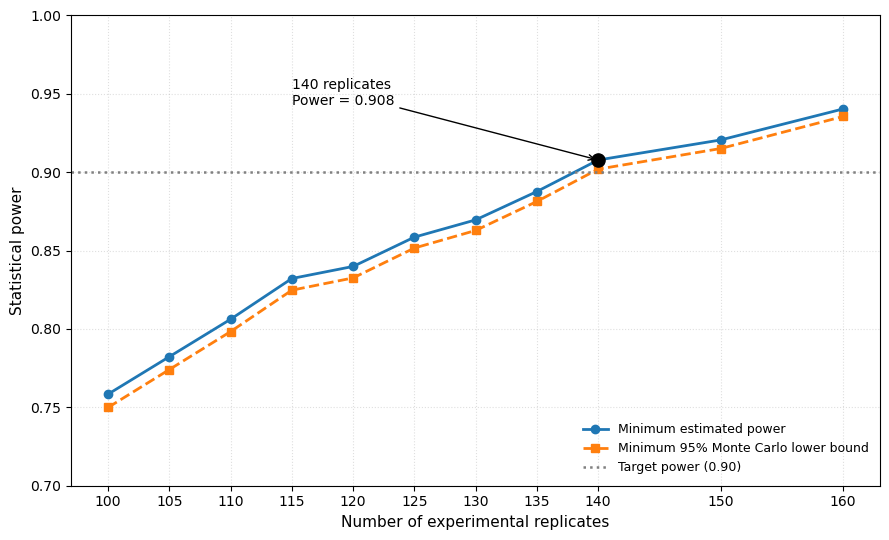

In [23]:
# Line graph for Figure 3

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the final power-analysis recommendations
df = pd.read_csv("joint_friedman_holm_recommendations_30000.csv")

# Keep the Conservative scenario and numerical replicate counts
df = df[df["Scenario"] == "Conservative"].copy()
df["Runs"] = pd.to_numeric(df["Runs"], errors="coerce")
df = df.dropna(subset=["Runs"]).sort_values("Runs")

# Extract the final simulation results
x = df["Runs"].to_numpy()
power = df["Minimum_Power"].to_numpy()
lower = df["Minimum_MC_Lower95"].to_numpy()

target_power = 0.90
selected_runs = 140

# Create the figure
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    x, power,
    marker="o", linewidth=2,
    label="Minimum estimated power"
)

ax.plot(
    x, lower,
    marker="s", linestyle="--", linewidth=2,
    label="Minimum 95% Monte Carlo lower bound"
)

ax.axhline(
    y=target_power,
    color="gray", linestyle=":",
    linewidth=1.8,
    label="Target power (0.90)"
)

# Highlight the selected number of replicates
selected = df[df["Runs"] == selected_runs]

if not selected.empty:
    selected_power = selected["Minimum_Power"].iloc[0]

    ax.scatter(
        selected_runs, selected_power,
        color="black", s=90, zorder=5
    )

    ax.annotate(
        f"140 replicates\nPower = {selected_power:.3f}",
        xy=(selected_runs, selected_power),
        xytext=(selected_runs - 25, selected_power + 0.035),
        arrowprops=dict(arrowstyle="->", color="black"),
        fontsize=10
    )

# Formatting
ax.set_xlabel("Number of experimental replicates", fontsize=11)
ax.set_ylabel("Statistical power", fontsize=11)

ax.set_xticks(x)
ax.set_ylim(0.70, 1.00)
ax.set_yticks(np.arange(0.70, 1.01, 0.05))

ax.grid(True, linestyle=":", alpha=0.4)
ax.legend(loc="lower right", fontsize=9, frameon=False)

plt.tight_layout()

# Save publication-quality versions
plt.savefig(
    "Figure_3_Simulation_Based_Power.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    "Figure_3_Simulation_Based_Power.pdf",
    bbox_inches="tight"
)

plt.show()
